## 1. Introduction

#### Molecular HIV Activity Prediction with Three GCN Variants
**AIMS master's thesis research — Paul Sanyang**

This research notebook implements **(1) node-only GCN**, **(2) additive edge-aware GCN** , and **(3) edge-weighted GCN** as a **new extension**. All models use the same official OGB scaffold split and training protocol.


## 2.  Setup
#### 2.Install dependencies. 

PyTorch Geometric installation depends on the installed PyTorch version; consult the [official installation guide](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html).

In [82]:
pwd

'/Users/paulsanyang/Desktop/Github_file/AMMI_Project_NEW'

In [3]:
%pip install torch-geometric
%pip install ogb rdkit scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


#### 2.2 Import necessary libraries

In [7]:
import os
import os.path as osp
import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.nn import Linear
import torch.nn.functional as F
import torch.optim as optim
import torch_geometric
from torch_geometric.loader import DataLoader
from torch_geometric.utils import to_dense_adj, to_dense_batch
from ogb.graphproppred import PygGraphPropPredDataset, Evaluator
from ogb.graphproppred.mol_encoder import AtomEncoder, BondEncoder
from rdkit import Chem
import matplotlib.pyplot as plt
import networkx as nx
from tqdm.auto import tqdm
import copy
import random

print('PyTorch:', torch.__version__, '| PyG:', torch_geometric.__version__)

/opt/anaconda3/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.15.0 | PyG: 2.8.1


In [9]:
# Automatically select the best available device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")


Using device: mps


## 3. Dataset Preparation and Exploratory Analysis

Each graph represents a molecule: atoms are nodes, chemical bonds are edges, and the target is a binary activity label. We use the official OGB **scaffold** split for training, validation, and final testing. The test set is not used to choose architectures or checkpoints.

#### 3.1 Dataset Splitting and Data Loaders

In [13]:
# The official OGB dataset is downloaded/cached in ./data
# Some OGB versions use torch.load without weights_only=False, which PyTorch 2.6+ requires
DATA_ROOT = './data'
_original_load = torch.load
def _trusted_ogb_load(*args, **kwargs):
    kwargs.setdefault('weights_only', False)
    return _original_load(*args, **kwargs)
try:
    torch.load = _trusted_ogb_load
    dataset = PygGraphPropPredDataset(name='ogbg-molhiv', root=DATA_ROOT)
finally:
    torch.load = _original_load
split_idx = dataset.get_idx_split()
batch_size = 32
train_loader = DataLoader(dataset[split_idx['train']], batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(dataset[split_idx['valid']], batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset[split_idx['test']], batch_size=batch_size, shuffle=False)
print('Graphs:', len(dataset), '| splits:', {k: len(v) for k,v in split_idx.items()})

Graphs: 41127 | splits: {'train': 32901, 'valid': 4113, 'test': 4113}


In [15]:
labels = dataset.y.view(-1)
inactive = int((labels == 0).sum())
active = int((labels == 1).sum())
print(f'Inactive: {inactive:,} | Active: {active:,} | Total: {len(labels):,}')
print('Example node features:', tuple(dataset[0].x.shape), 'bond features:', tuple(dataset[0].edge_attr.shape))

Inactive: 39,684 | Active: 1,443 | Total: 41,127
Example node features: (19, 9) bond features: (40, 3)


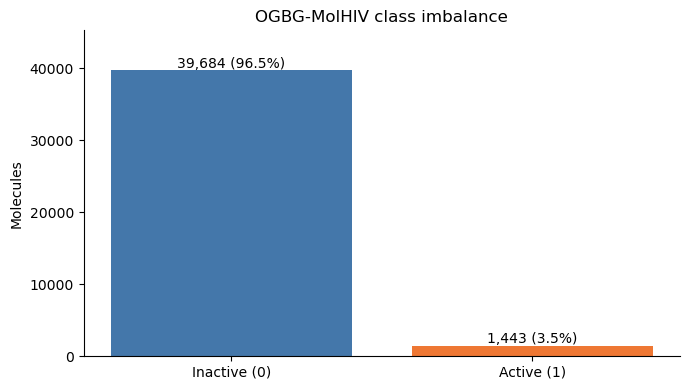

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = [inactive, active]
bars = ax.bar(['Inactive (0)', 'Active (1)'], counts, color=['#4477AA', '#EE7733'])
for bar, count in zip(bars, counts):
    ax.text(bar.get_x()+bar.get_width()/2, count+350, f'{count:,} ({100*count/len(labels):.1f}%)', ha='center')
ax.set_ylim(0, max(counts)*1.14)
ax.set(title='OGBG-MolHIV class imbalance', ylabel='Molecules')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

#### 3.2 Exploratory Analysis of Molecular Bond Features

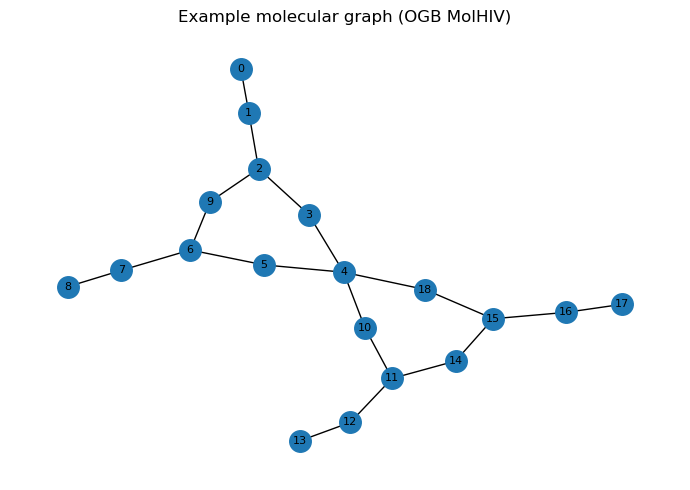

In [20]:
# Illustrative molecular graph: nodes represent atoms and edges represent bonds
graph = dataset[0]
graph_nx = torch_geometric.utils.to_networkx(graph, to_undirected=True)
plt.figure(figsize=(7, 5))
nx.draw_networkx(graph_nx, pos=nx.spring_layout(graph_nx, seed=42), node_size=240,
                 font_size=8, with_labels=True)
plt.title('Example molecular graph (OGB MolHIV)')
plt.axis('off')
plt.tight_layout()
plt.show()

   HIV_active                                             smiles  mol_id
0           0  CCC1=[O+][Cu-3]2([O+]=C(CC)C1)[O+]=C(CC)CC(CC)...     NaN
1           0  C(=Cc1ccccc1)C1=[O+][Cu-3]2([O+]=C(C=Cc3ccccc3...     NaN
2           0                   CC(=O)N1c2ccccc2Sc2c1ccc1ccccc21     NaN
3           0    Nc1ccc(C=Cc2ccc(N)cc2S(=O)(=O)O)c(S(=O)(=O)O)c1     NaN
4           0                             O=S(=O)(O)CCS(=O)(=O)O     NaN


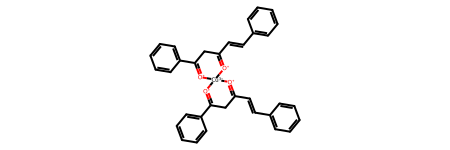

In [22]:
from pathlib import Path
from rdkit.Chem.Draw import IPythonConsole

# Locate the SMILES mapping file
smiles_path = Path(dataset.root) / "mapping" / "mol.csv.gz"

# Load molecular SMILES
smiles_df = pd.read_csv(smiles_path)

print(smiles_df.head())

# Select molecule number 1
smiles = smiles_df.iloc[1]["smiles"]

# Convert SMILES into an RDKit molecule
mol = Chem.MolFromSmiles(smiles)

# Display the molecular structure in Jupyter
mol


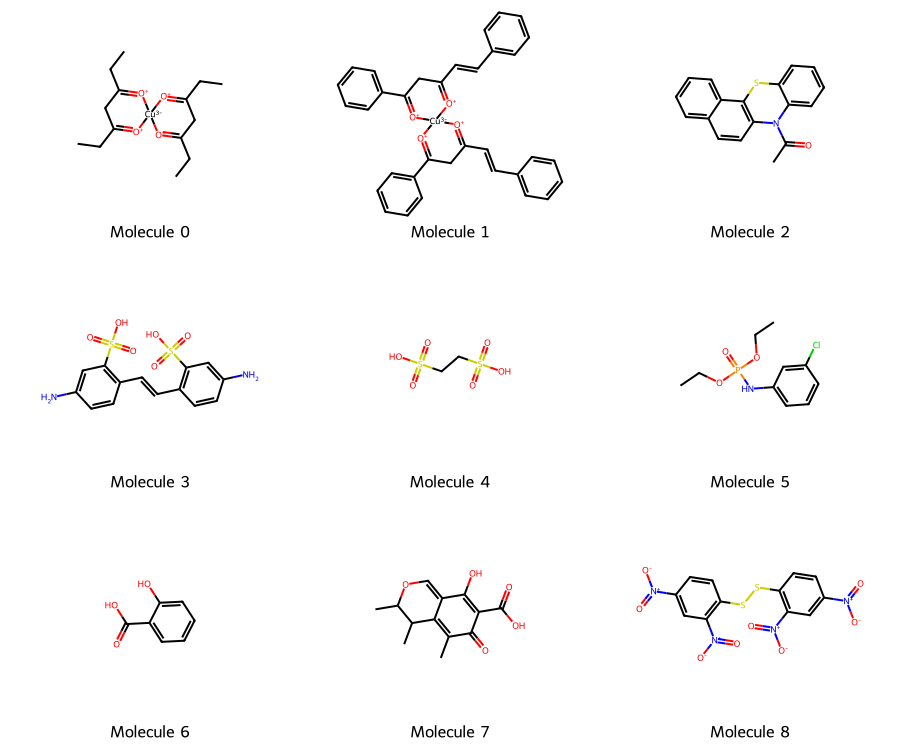

In [24]:
from rdkit.Chem import Draw
molecules = [
    Chem.MolFromSmiles(s)
    for s in smiles_df["smiles"].iloc[:9]]

img = Draw.MolsToGridImage(
    molecules,
    molsPerRow=3,
    subImgSize=(300, 250),
    legends=[f"Molecule {i}" for i in range(9)])

display(img)


#### 3.3 Molecular Bond Features

In [27]:
batch = next(iter(train_loader))

print("Edge attribute shape:", batch.edge_attr.shape)
print("First 10 bond feature vectors:")
print(batch.edge_attr[:10])

print("\nUnique values for each bond feature:")

for j in range(batch.edge_attr.shape[1]):
    print(
        f"Feature {j}:",
        torch.unique(batch.edge_attr[:, j]).tolist()
    )

Edge attribute shape: torch.Size([1792, 3])
First 10 bond feature vectors:
tensor([[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 1],
        [0, 0, 1],
        [1, 0, 1],
        [1, 0, 1]])

Unique values for each bond feature:
Feature 0: [0, 1, 2, 3]
Feature 1: [0]
Feature 2: [0, 1]


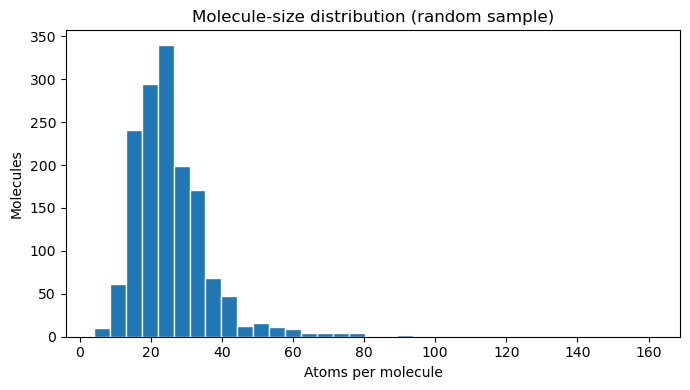

In [29]:
# Distribution of molecule sizes (number of atoms)
rng = np.random.default_rng(5)
subset = rng.choice(len(dataset), size=min(1500, len(dataset)), replace=False)
atom_counts = [dataset[int(i)].num_nodes for i in subset]
plt.figure(figsize=(7, 4))
plt.hist(atom_counts, bins=35, edgecolor='white')
plt.xlabel('Atoms per molecule')
plt.ylabel('Molecules')
plt.title('Molecule-size distribution (random sample)')
plt.tight_layout()
plt.show()

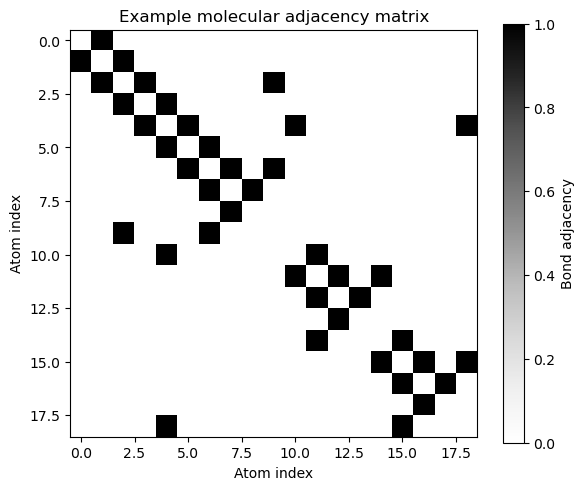

In [31]:
# Example atom adjacency matrix
example = dataset[0]
a = to_dense_adj(example.edge_index, max_num_nodes=example.num_nodes)[0].cpu().numpy()
plt.figure(figsize=(6, 5))
plt.imshow(a, interpolation='nearest', cmap='Greys')
plt.colorbar(label='Bond adjacency')
plt.title('Example molecular adjacency matrix')
plt.xlabel('Atom index')
plt.ylabel('Atom index')
plt.tight_layout()
plt.show()

## 4. Graph Neural Network Architectures
##### Three message-passing approaches

#### 4.1.1 Standard Graph Convolutional Network

$$
\hat A=\tilde D^{-1/2}(A+I)\tilde D^{-1/2},\qquad
h_i^{(l+1)}=\mathrm{ReLU}\left(W^{(l)}\sum_j\hat A_{ij}h_j^{(l)}+b^{(l)}\right).
$$

#### 4.1.2 Additive Edge-Aware GCN

$$
m_{ij}^{(l)}=h_j^{(l)}+e_{ij},\qquad
h_i^{(l+1)}=\mathrm{ReLU}\left(W^{(l)}\left[\sum_j\hat A_{ij}h_j^{(l)}+\sum_{j:(i,j)\in E}\hat A_{ij}e_{ij}\right]+b^{(l)}\right).
$$

The bond embeddings $e_{ij}$ have the same hidden dimension as the atom embeddings. Self-loops contribute atom messages but **no artificial bond messages**.

#### 4.1.3 Edge-Weighted GCN

$$
w_{ij}^{(l)}=2\,\mathrm{sigmoid}\left(u_l^\top e_{ij}+c_l\right),\quad
\tilde A^{(l)}_{ij}=A_{ij}w_{ij}^{(l)}+I_{ij},\quad
\hat A^{(l)}=(\tilde D^{(l)})^{-1/2}\tilde A^{(l)}(\tilde D^{(l)})^{-1/2}.
$$

This approach **scales** the contribution of a neighbouring atom instead of adding the bond representation to the message.


In [34]:
class CustomGCNLayer(nn.Module):
    """Dense GCN layer: none, additive, or weighted bond integration."""
    def __init__(self, hidden_dim, edge_mode='weighted'):
        super().__init__()
        if edge_mode not in {'none', 'additive', 'weighted'}:
            raise ValueError('edge_mode must be none, additive, or weighted')
        self.edge_mode = edge_mode
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.edge_weight = nn.Linear(hidden_dim, 1) if edge_mode == 'weighted' else None

    def forward(self, x, adj, bond_emb=None):
        # x: [B,N,H]; adj: [B,N,N]; bond_emb: [B,N,N,H]
        if self.edge_mode != 'none' and bond_emb is None:
            raise ValueError('Edge-aware mode requires bond embeddings')
        n = adj.size(-1)
        eye = torch.eye(n, device=adj.device, dtype=adj.dtype).unsqueeze(0)
        if self.edge_mode == 'weighted':
            edge_weights = 2.0 * torch.sigmoid(self.edge_weight(bond_emb).squeeze(-1))
            a_tilde = adj * edge_weights + eye
        else:
            a_tilde = adj + eye
        degree = a_tilde.sum(dim=-1).clamp(min=1)
        inv = degree.pow(-0.5)
        normalized = inv.unsqueeze(-1) * a_tilde * inv.unsqueeze(-2)
        messages = normalized @ x
        if self.edge_mode == 'additive':
            # Only original edges carry bond information; no self-loop bond embedding.
            messages = messages + ((normalized * adj).unsqueeze(-1) * bond_emb).sum(dim=2)
        return self.linear(messages)

class MolecularGCN(nn.Module):
    def __init__(self, hidden_dim=64, num_layers=4, edge_mode='none'):
        super().__init__()
        self.edge_mode = edge_mode
        self.atom_encoder = AtomEncoder(hidden_dim)
        self.bond_encoder = BondEncoder(hidden_dim) if edge_mode != 'none' else None
        self.convs = nn.ModuleList([CustomGCNLayer(hidden_dim, edge_mode) for _ in range(num_layers)])
        self.classifier = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        h = self.atom_encoder(data.x.long())
        h, mask = to_dense_batch(h, batch=data.batch)
        n = h.size(1)
        adj = to_dense_adj(data.edge_index, batch=data.batch, max_num_nodes=n)
        bonds = None
        if self.edge_mode != 'none':
            encoded_bonds = self.bond_encoder(data.edge_attr.long())
            bonds = to_dense_adj(data.edge_index, batch=data.batch,
                                 edge_attr=encoded_bonds, max_num_nodes=n)
        for conv in self.convs:
            h = F.relu(conv(h, adj, bonds))
            h = h * mask.unsqueeze(-1)
        pooled = h.sum(dim=1)  # sum pooling over actual nodes only
        return self.classifier(pooled)  # logits; BCEWithLogitsLoss


#### 4.2 Minimal shape and gradient checks

These quick tests catch dimension errors and verify that the bond-dependent parameters participate in backpropagation. They do **not** establish full training reproducibility.

In [37]:
sample_batch = next(iter(train_loader))
for mode in ('none', 'additive', 'weighted'):
    probe = MolecularGCN(edge_mode=mode)
    logits = probe(sample_batch)
    assert logits.shape == (sample_batch.num_graphs, 1)
    logits.sum().backward()
    if mode == 'weighted':
        assert probe.convs[0].edge_weight.weight.grad is not None
    if mode != 'none':
        assert any(p.grad is not None for p in probe.bond_encoder.parameters())
    print(mode, '✓', tuple(logits.shape), 'parameters:', sum(p.numel() for p in probe.parameters()))

none ✓ (32, 1) parameters: 27841
additive ✓ (32, 1) parameters: 28673
weighted ✓ (32, 1) parameters: 28933


## 5. Model Training and Evaluation 
#### 5.1 Training Configuration and Hyperparameters

- Four GCN layers, hidden dimension 64, Adam learning rate 0.001, batch size 32.
- Default **2 epochs** for a quick smoke test; use **120** for a thesis-length run.
- Each mode is trained **from scratch** with the same seed and split.
- Select the best checkpoint by **validation ROC-AUC**, not the last epoch.
- Run the **test set only after model selection is finalized**. The final-test flag is disabled by default.
- Full-data train ROC-AUC each epoch is optional and can make training substantially slower.

**Memory note:** Dense adjacency has $O(BN^2)$ memory usage. Lower the batch size if you run out of memory. MPS can be enabled in the device cell, but PyG operations may require CPU fallback.

#### 5.2 Training and Evaluation Functions

In [43]:
##
SEED = 5
EPOCHS = 65            # Change to 120 for a full experiment
MODES = ('none', 'additive', 'weighted')
RUN_FINAL_TEST = False  # Set True only after architecture/model selection is frozen
TRACK_TRAIN_AUC = False  # Full training-set AUC each epoch is expensive

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

criterion = nn.BCEWithLogitsLoss()
evaluator = Evaluator(name='ogbg-molhiv')

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    total_count = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch)
        targets = batch.y.float().view_as(logits)
        valid = ~torch.isnan(targets)
        if not valid.any():
            continue
        loss = criterion(logits[valid], targets[valid])
        loss.backward()
        optimizer.step()
        count = int(valid.sum().item())
        total_loss += loss.item() * count
        total_count += count
    return total_loss / max(total_count, 1)

@torch.no_grad()
def evaluate_auc(model, loader):
    model.eval()
    targets, predictions = [], []
    for batch in loader:
        batch = batch.to(device)
        logits = model(batch)
        targets.append(batch.y.cpu())
        predictions.append(torch.sigmoid(logits).cpu())
    result = evaluator.eval({'y_true': torch.cat(targets, dim=0),
                             'y_pred': torch.cat(predictions, dim=0)})
    return float(result['rocauc'])


#### 5.3 Model Training and Checkpoint Selection

In [46]:
results = {}
histories = {}
selected_models = {}

for mode in MODES:
    seed_everything(SEED)
    model = MolecularGCN(hidden_dim=64, num_layers=4, edge_mode=mode).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    history = {'epoch': [], 'loss': [], 'valid_auc': [], 'train_auc': []}
    best_auc = -float('inf')
    best_state = None
    best_epoch = None
    print(f'\nTraining {mode} GCN on {device}')

    for epoch in range(1, EPOCHS + 1):
        loss = train_epoch(model, train_loader, optimizer)
        val_auc = evaluate_auc(model, valid_loader)
        train_auc = evaluate_auc(model, train_loader) if TRACK_TRAIN_AUC else float('nan')
        history['epoch'].append(epoch)
        history['loss'].append(loss)
        history['valid_auc'].append(val_auc)
        history['train_auc'].append(train_auc)
        if np.isfinite(val_auc) and val_auc > best_auc:
            best_auc = val_auc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(f'Epoch {epoch:3d} | loss={loss:.4f} | valid ROC-AUC={val_auc:.4f}')

    if best_state is None:
        raise RuntimeError(f'No valid validation ROC-AUC for {mode}')
    model.load_state_dict(best_state)
    histories[mode] = history
    selected_models[mode] = model
    results[mode] = {'best_epoch': best_epoch, 'validation_rocauc': best_auc}
    print(f'Best checkpoint: epoch {best_epoch}; validation ROC-AUC={best_auc:.4f}')

print('\nNew validation results (NOT thesis historical results):')
print(pd.DataFrame(results).T.to_string())


Training none GCN on mps
Epoch   1 | loss=0.2205 | valid ROC-AUC=0.4888
Epoch   5 | loss=0.1486 | valid ROC-AUC=0.6069
Epoch  10 | loss=0.1345 | valid ROC-AUC=0.7331
Epoch  15 | loss=0.1257 | valid ROC-AUC=0.7611
Epoch  20 | loss=0.1200 | valid ROC-AUC=0.7549
Epoch  25 | loss=0.1167 | valid ROC-AUC=0.7649
Epoch  30 | loss=0.1143 | valid ROC-AUC=0.8063
Epoch  35 | loss=0.1108 | valid ROC-AUC=0.7751
Epoch  40 | loss=0.1081 | valid ROC-AUC=0.8000
Epoch  45 | loss=0.1051 | valid ROC-AUC=0.7343
Epoch  50 | loss=0.1019 | valid ROC-AUC=0.7703
Epoch  55 | loss=0.1005 | valid ROC-AUC=0.8125
Epoch  60 | loss=0.0981 | valid ROC-AUC=0.7860
Epoch  65 | loss=0.0961 | valid ROC-AUC=0.7784
Best checkpoint: epoch 27; validation ROC-AUC=0.8156

Training additive GCN on mps
Epoch   1 | loss=0.2159 | valid ROC-AUC=0.4852
Epoch   5 | loss=0.1504 | valid ROC-AUC=0.6703
Epoch  10 | loss=0.1320 | valid ROC-AUC=0.6172
Epoch  15 | loss=0.1228 | valid ROC-AUC=0.7004
Epoch  20 | loss=0.1184 | valid ROC-AUC=0.698

## 6. Experimental Results and Model Comparison
#### 6.1 Validation ROC-AUC and Parameter Comparison

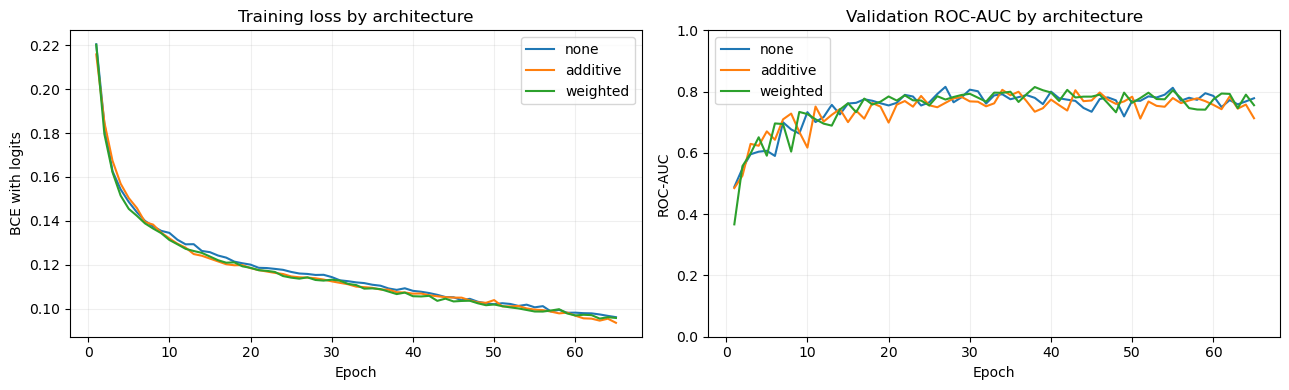

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for mode, history in histories.items():
    axes[0].plot(history['epoch'], history['loss'], label=mode)
    axes[1].plot(history['epoch'], history['valid_auc'], label=mode)
axes[0].set(title='Training loss by architecture', xlabel='Epoch', ylabel='BCE with logits')
axes[1].set(title='Validation ROC-AUC by architecture', xlabel='Epoch', ylabel='ROC-AUC', ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 6.2 Training Dynamics and Validation Performance

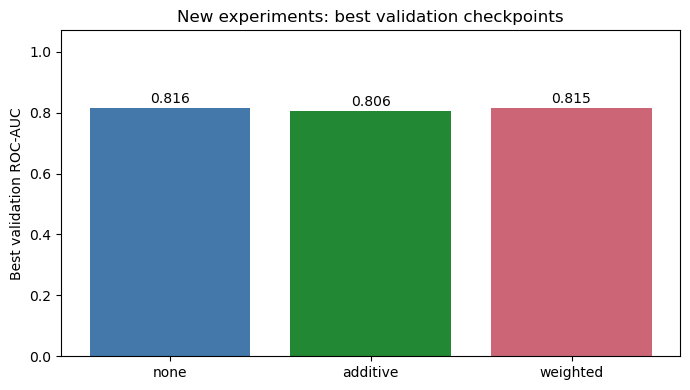

In [54]:
names = list(results)
values = [results[m]['validation_rocauc'] for m in names]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(names, values, color=['#4477AA', '#228833', '#CC6677'])
for bar, value in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.015, f'{value:.3f}', ha='center')
ax.set(ylim=(0, 1.07), ylabel='Best validation ROC-AUC', title='New experiments: best validation checkpoints')
plt.tight_layout(); plt.show()

#### Models

In [57]:
# baseline_model = selected_models['none']
# additive_model = selected_models['additive']
# weighted_model = selected_models['weighted']
# mpnn_model = selected_models['mpnn']

#### 6.3 Test-Set Evaluation of Selected Models
**Keep `RUN_FINAL_TEST=False` while developing.** After deciding which architecture(s) to report using validation results, set it to `True` **once**. Do not repeatedly tune the architecture based on the resulting test scores.

In [60]:
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    for mode, model in selected_models.items():
        results[mode]['test_rocauc'] = evaluate_auc(model, test_loader)
    print('FINAL held-out test results (new experiments):')
    print(pd.DataFrame(results).T.to_string())
else:
    print('Held-out test evaluation skipped (RUN_FINAL_TEST=False).')

FINAL held-out test results (new experiments):
          best_epoch  validation_rocauc  test_rocauc
none            27.0           0.815645     0.757000
additive        34.0           0.805889     0.764930
weighted        38.0           0.814907     0.750262


## 7. Diagnostic Analysis of Edge-Aware Learning
#### 7.1 Symmetry of Learned Edge Weights
This checks whether your trained model assigns equal weights to both directions of the same chemical bond.

In [63]:
model = selected_models['weighted']
model.eval()

batch = next(iter(train_loader)).to(device)

with torch.no_grad():
    encoded_bonds = model.bond_encoder(
        batch.edge_attr.long()
    )

    h = model.atom_encoder(batch.x.long())
    h, mask = to_dense_batch(h, batch=batch.batch)
    n = h.size(1)

    adj = to_dense_adj(
        batch.edge_index,
        batch=batch.batch,
        max_num_nodes=n
    )

    bonds = to_dense_adj(
        batch.edge_index,
        batch=batch.batch,
        edge_attr=encoded_bonds,
        max_num_nodes=n
    )

    for i, conv in enumerate(model.convs):
        edge_weights = 2.0 * torch.sigmoid(
            conv.edge_weight(bonds).squeeze(-1)
        )

        weighted_adj = adj * edge_weights

        asymmetry = (
            weighted_adj -
            weighted_adj.transpose(1, 2)
        ).abs().max()

        print(
            f"Layer {i+1} maximum asymmetry: "
            f"{asymmetry.item():.10f}"
        )


Layer 1 maximum asymmetry: 0.0000000000
Layer 2 maximum asymmetry: 0.0000000000
Layer 3 maximum asymmetry: 0.0000000000
Layer 4 maximum asymmetry: 0.0000000000


#### 7.2 Distribution of Learned Weights by Chemical Bond Type

In [66]:


model = selected_models['weighted']
model.eval()

batch = next(iter(train_loader)).to(device)

bond_names = {
    0: "Single",
    1: "Double",
    2: "Triple",
    3: "Aromatic"
}

with torch.no_grad():
    bond_emb = model.bond_encoder(
        batch.edge_attr.long())

    bond_types = batch.edge_attr[:, 0]

    for layer_idx, conv in enumerate(model.convs):
        weights = 2.0 * torch.sigmoid(
            conv.edge_weight(bond_emb).squeeze(-1))

        print(f"\nLayer {layer_idx + 1}")

        for bond_type in torch.unique(bond_types).tolist():
            selected = weights[bond_types == bond_type]

            print(
                f"{bond_names.get(bond_type, str(bond_type))}: "
                f"count={selected.numel()}, "
                f"mean={selected.mean().item():.6f}, "
                f"std={selected.std(unbiased=False).item():.6f}")


Layer 1
Single: count=1034, mean=1.977911, std=0.005943
Double: count=162, mean=1.177076, std=0.106914
Triple: count=8, mean=1.345654, std=0.111846
Aromatic: count=596, mean=0.000208, std=0.000000

Layer 2
Single: count=1034, mean=1.999940, std=0.000084
Double: count=162, mean=1.976566, std=0.011095
Triple: count=8, mean=1.923397, std=0.100863
Aromatic: count=596, mean=0.000000, std=0.000000

Layer 3
Single: count=1034, mean=1.859904, std=0.075684
Double: count=162, mean=1.483464, std=0.651746
Triple: count=8, mean=1.089327, std=0.504930
Aromatic: count=596, mean=1.999800, std=0.000000

Layer 4
Single: count=1034, mean=1.343705, std=0.724962
Double: count=162, mean=1.243087, std=0.388330
Triple: count=8, mean=1.167168, std=0.666399
Aromatic: count=596, mean=0.000000, std=0.000000


#### 7.3 Analysis of Edge-Weight Parameter Updates
This examines whether the parameters of your trained weighted GCN changed from their zero-initialised values. This section assumes that you trained the model using zero initialisation. If you used a different initialisation, nonzero final parameters alone do not prove how much they changed during training.

In [69]:
model = selected_models['weighted']
model.eval()

print("Edge-Weight Parameter Analysis")

for i, conv in enumerate(model.convs):
    W = conv.edge_weight.weight.detach()
    b = conv.edge_weight.bias.detach()

    print(f"\nLayer {i + 1}")

    print(
        f"Weight maximum absolute value: "
        f"{W.abs().max().item():.10f}"
    )

    print(
        f"Weight mean absolute value: "
        f"{W.abs().mean().item():.10f}"
    )

    print(
        f"Bias absolute value: "
        f"{b.abs().max().item():.10f}"
    )


Edge-Weight Parameter Analysis

Layer 1
Weight maximum absolute value: 0.4244619906
Weight mean absolute value: 0.1469480097
Bias absolute value: 0.1209526584

Layer 2
Weight maximum absolute value: 1.0377042294
Weight mean absolute value: 0.4071921706
Bias absolute value: 0.3762497604

Layer 3
Weight maximum absolute value: 0.6820359826
Weight mean absolute value: 0.1838405877
Bias absolute value: 0.2342894822

Layer 4
Weight maximum absolute value: 0.8306715488
Weight mean absolute value: 0.2558940053
Bias absolute value: 0.0104978252


### 7.4 Check edge-weight gradients

In [72]:

# Gradient Analysis of Edge-Weight Parameters

model = selected_models['weighted']
model.train()

batch = next(iter(train_loader)).to(device)

model.zero_grad(set_to_none=True)

logits = model(batch).view(-1)
targets = batch.y.float().view(-1)

valid = torch.isfinite(targets)

loss = torch.nn.functional.binary_cross_entropy_with_logits(
    logits[valid],
    targets[valid]
)

loss.backward()

for i, conv in enumerate(model.convs):
    grad_W = conv.edge_weight.weight.grad
    grad_b = conv.edge_weight.bias.grad

    print(f"\nLayer {i + 1}")

    print(
        "Weight gradient max:",
        None if grad_W is None
        else f"{grad_W.abs().max().item():.10f}"
    )

    print(
        "Bias gradient max:",
        None if grad_b is None
        else f"{grad_b.abs().max().item():.10f}"
    )

model.zero_grad(set_to_none=True)
model.eval()


Layer 1
Weight gradient max: 0.0005648776
Bias gradient max: 0.0010636759

Layer 2
Weight gradient max: 0.0000362672
Bias gradient max: 0.0000021359

Layer 3
Weight gradient max: 0.0011655221
Bias gradient max: 0.0011382361

Layer 4
Weight gradient max: 0.0005147106
Bias gradient max: 0.0001978480


MolecularGCN(
  (atom_encoder): AtomEncoder(
    (atom_embedding_list): ModuleList(
      (0): Embedding(119, 64)
      (1): Embedding(5, 64)
      (2-3): 2 x Embedding(12, 64)
      (4): Embedding(10, 64)
      (5-6): 2 x Embedding(6, 64)
      (7-8): 2 x Embedding(2, 64)
    )
  )
  (bond_encoder): BondEncoder(
    (bond_embedding_list): ModuleList(
      (0): Embedding(5, 64)
      (1): Embedding(6, 64)
      (2): Embedding(2, 64)
    )
  )
  (convs): ModuleList(
    (0-3): 4 x CustomGCNLayer(
      (linear): Linear(in_features=64, out_features=64, bias=True)
      (edge_weight): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)

In [74]:
print('PyTorch:', torch.__version__)
print('PyG:', torch_geometric.__version__)
print('Device:', device)
print('Seed:', SEED, '| epochs:', EPOCHS, '| batch size:', batch_size)
print('Model modes:', MODES)

PyTorch: 2.15.0
PyG: 2.8.1
Device: mps
Seed: 5 | epochs: 65 | batch size: 32
Model modes: ('none', 'additive', 'weighted')
